1. SciCite Dataset Loading

In [2]:
import pandas as pd
import requests
import tarfile
import io
import json

url = "https://s3-us-west-2.amazonaws.com/ai2-s2-research/scicite/scicite.tar.gz"
response = requests.get(url, timeout=120)
response.raise_for_status()

data = {}

with tarfile.open(fileobj=io.BytesIO(response.content), mode="r:gz") as archive:
    for split, filename in [
        ("train", "scicite/train.jsonl"),
        ("validation", "scicite/dev.jsonl"),
        ("test", "scicite/test.jsonl")
    ]:
        file = archive.extractfile(filename)
        rows = [json.loads(line) for line in file]
        data[split] = pd.DataFrame(rows)

train = data["train"].drop_duplicates(subset="unique_id").copy()
val = data["validation"].drop_duplicates(subset="unique_id").copy()
test = data["test"].drop_duplicates(subset="unique_id").copy()

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))
print("Columns:", train.columns.tolist())
print("Missing text:", train["string"].isna().sum())
print("Labels:", train["label"].value_counts().to_dict())
print("Dataset loaded successfully")

Train: 8194
Validation: 916
Test: 1859
Columns: ['source', 'citeEnd', 'sectionName', 'citeStart', 'string', 'label', 'label_confidence', 'citingPaperId', 'citedPaperId', 'isKeyCitation', 'id', 'unique_id', 'excerpt_index', 'label2', 'label2_confidence']
Missing text: 0
Labels: {'background': 4840, 'method': 2266, 'result': 1088}
Dataset loaded successfully


2. TF-IDF + Logistic Regression

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report

model = make_pipeline(
    TfidfVectorizer(max_features=20000, ngram_range=(1, 2)),
    LogisticRegression(max_iter=1000, random_state=42)
)

model.fit(train["string"], train["label"])

pred = model.predict(val["string"])

print("Accuracy:", accuracy_score(val["label"], pred))
print("Macro F1:", f1_score(val["label"], pred, average="macro"))
print("\nClassification Report:")
print(classification_report(val["label"], pred))

Accuracy: 0.8275109170305677
Macro F1: 0.7924561902181647

Classification Report:
              precision    recall  f1-score   support

  background       0.81      0.94      0.87       538
      method       0.86      0.68      0.76       255
      result       0.88      0.65      0.75       123

    accuracy                           0.83       916
   macro avg       0.85      0.76      0.79       916
weighted avg       0.83      0.83      0.82       916



3. Linear SVM Baseline

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

svm_model = make_pipeline(
    TfidfVectorizer(max_features=20000, ngram_range=(1, 2)),
    LinearSVC(random_state=42)
)

svm_model.fit(train["string"], train["label"])

svm_pred = svm_model.predict(val["string"])

svm_accuracy = accuracy_score(val["label"], svm_pred)
svm_f1 = f1_score(val["label"], svm_pred, average="macro")

print("Linear SVM Baseline")
print("Accuracy:", svm_accuracy)
print("Macro F1:", svm_f1)
print("\nClassification Report:")
print(classification_report(val["label"], svm_pred))

Linear SVM Baseline
Accuracy: 0.8286026200873362
Macro F1: 0.803179860972748

Classification Report:
              precision    recall  f1-score   support

  background       0.83      0.90      0.87       538
      method       0.82      0.72      0.77       255
      result       0.82      0.74      0.78       123

    accuracy                           0.83       916
   macro avg       0.82      0.79      0.80       916
weighted avg       0.83      0.83      0.83       916



4. Baseline Comparison and Error Analysis

Baseline Comparison and Error Analysis

Baseline Comparison:
              Model  Accuracy  Macro F1
Logistic Regression  0.827511  0.792456
         Linear SVM  0.828603  0.803180


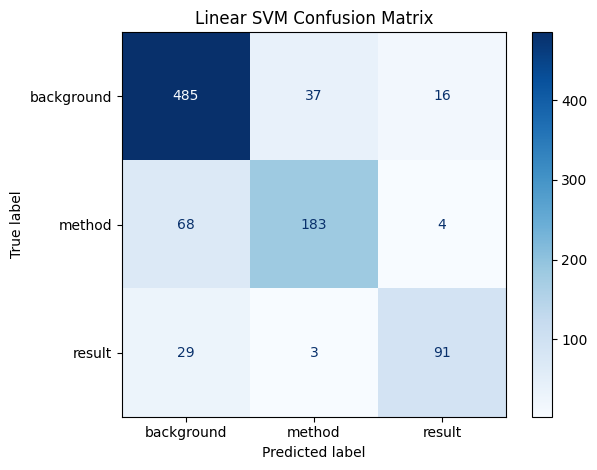


Total SVM Errors: 157

Sample Misclassifications:
                                                                                    string      label  predicted
At present, whether the contrasting results obtained with b-sitosterol are due to diffe...     result background
Similar logic has been applied to other medical devices, particularly those fixated in ... background     method
In this section we recall the standard quantization of a scalar field used in LQG [8, 9... background     method
The temperament domains are Novelty Seeking, Harm Avoidance, Reward Dependence, and Per... background     method
As opposed to earlier studies (Cook et al., 2007; Bannard, 2007; Tan et al., 2006), we ...     method     result

Saved:
baseline_comparison.csv
svm_confusion_matrix.png
svm_errors.csv


In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

print("Baseline Comparison and Error Analysis")

labels = ["background", "method", "result"]

results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(val["label"], pred),
        "Macro F1": f1_score(val["label"], pred, average="macro")
    },
    {
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(val["label"], svm_pred),
        "Macro F1": f1_score(val["label"], svm_pred, average="macro")
    }
])

print("\nBaseline Comparison:")
print(results.to_string(index=False))

results.to_csv("baseline_comparison.csv", index=False)

cm = confusion_matrix(val["label"], svm_pred, labels=labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Linear SVM Confusion Matrix")
plt.tight_layout()
plt.savefig("svm_confusion_matrix.png", dpi=300)
plt.show()

errors = val[["string", "label"]].copy()
errors["predicted"] = svm_pred
errors = errors[errors["label"] != errors["predicted"]]

print("\nTotal SVM Errors:", len(errors))
print("\nSample Misclassifications:")
print(errors.head(5).to_string(index=False, max_colwidth=90))

errors.to_csv("svm_errors.csv", index=False)

print("\nSaved:")
print("baseline_comparison.csv")
print("svm_confusion_matrix.png")
print("svm_errors.csv")

5. Data Leakage and Overlap Audit

In [8]:

import pandas as pd

print("Data Leakage and Overlap Audit")

splits = {
    "train": train,
    "validation": val,
    "test": test
}

for name, df in splits.items():
    print(f"\n{name.upper()}")
    print("Records:", len(df))
    print("Duplicate text:", df["string"].duplicated().sum())
    print("Duplicate IDs:", df["unique_id"].duplicated().sum())
    print("Unique citing papers:", df["citingPaperId"].nunique())

pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for a, b in pairs:
    df1, df2 = splits[a], splits[b]

    texts1 = set(df1["string"])
    texts2 = set(df2["string"])

    papers1 = set(df1["citingPaperId"].dropna())
    papers2 = set(df2["citingPaperId"].dropna())

    print(f"\n{a} vs {b}")
    print("Shared text contexts:", len(texts1 & texts2))
    print("Shared citing papers:", len(papers1 & papers2))

overlap = val[val["string"].isin(set(train["string"]))]

print("\nValidation records with training text:")
print(overlap[["unique_id", "label", "string"]].to_string(index=False, max_colwidth=100))

overlap.to_csv("train_validation_overlap.csv", index=False)

print("\nSaved: train_validation_overlap.csv")

Data Leakage and Overlap Audit

TRAIN
Records: 8194
Duplicate text: 1
Duplicate IDs: 0
Unique citing papers: 4664

VALIDATION
Records: 916
Duplicate text: 0
Duplicate IDs: 0
Unique citing papers: 817

TEST
Records: 1859
Duplicate text: 0
Duplicate IDs: 0
Unique citing papers: 1845

train vs validation
Shared text contexts: 2
Shared citing papers: 468

train vs test
Shared text contexts: 0
Shared citing papers: 226

validation vs test
Shared text contexts: 0
Shared citing papers: 59

Validation records with training text:
                                                                          unique_id  label                                                                                               string
fc76327ac26d573283db98939119660588c2af6f>be043e5abc540ceb03d56f1af6c00bae6c1d7aa9_0 method Although these twomethods described above were originally proposed for single-shell data, they ca...
0f6eb29bb841f995dc63b78b34d23cb597f8c973>f3ae074a4b8c62f34dff16e623cd09d05effde59_0 resul

6. Leakage-Controlled Baseline Evaluation

In [9]:
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report

print("Leakage-Controlled Baseline Evaluation")

mask = ~val["string"].isin(set(train["string"]))

clean_val = val.loc[mask].copy()
clean_lr_pred = pred[mask.to_numpy()]
clean_svm_pred = svm_pred[mask.to_numpy()]

print("Original validation:", len(val))
print("Removed overlaps:", len(val) - len(clean_val))
print("Clean validation:", len(clean_val))

results_clean = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(clean_val["label"], clean_lr_pred),
        "Macro_F1": f1_score(clean_val["label"], clean_lr_pred, average="macro")
    },
    {
        "Model": "Linear SVM",
        "Accuracy": accuracy_score(clean_val["label"], clean_svm_pred),
        "Macro_F1": f1_score(clean_val["label"], clean_svm_pred, average="macro")
    }
])

print("\nClean Baseline Comparison:")
print(results_clean.to_string(index=False))

print("\nLinear SVM Classification Report:")
print(classification_report(clean_val["label"], clean_svm_pred))

results_clean.to_csv("baseline_clean_results.csv", index=False)

print("\nSaved: baseline_clean_results.csv")

Leakage-Controlled Baseline Evaluation
Original validation: 916
Removed overlaps: 2
Clean validation: 914

Clean Baseline Comparison:
              Model  Accuracy  Macro_F1
Logistic Regression  0.827133  0.791313
         Linear SVM  0.828228  0.802213

Linear SVM Classification Report:
              precision    recall  f1-score   support

  background       0.83      0.90      0.87       538
      method       0.82      0.72      0.76       254
      result       0.82      0.74      0.78       122

    accuracy                           0.83       914
   macro avg       0.82      0.79      0.80       914
weighted avg       0.83      0.83      0.83       914


Saved: baseline_clean_results.csv


7. Prepare uncertainty-based verification

In [11]:
import numpy as np
import pandas as pd

print("SVM Uncertainty Scoring")

scores = svm_model.decision_function(clean_val["string"])

sorted_scores = np.sort(scores, axis=1)
margins = sorted_scores[:, -1] - sorted_scores[:, -2]

uncertainty_df = clean_val[["string", "label"]].copy()
uncertainty_df["predicted"] = clean_svm_pred
uncertainty_df["margin"] = margins
uncertainty_df["error"] = (
    uncertainty_df["label"] != uncertainty_df["predicted"]
)

uncertainty_df = uncertainty_df.sort_values("margin")

print("Total examples:", len(uncertainty_df))
print("Total errors:", uncertainty_df["error"].sum())

print("\n10 Most Uncertain Predictions:")
print(
    uncertainty_df[
        ["label", "predicted", "margin", "error"]
    ].head(10).to_string(index=False)
)

uncertainty_df.to_csv("svm_uncertainty_scores.csv", index=False)

print("\nSaved: svm_uncertainty_scores.csv")

SVM Uncertainty Scoring
Total examples: 914
Total errors: 157

10 Most Uncertain Predictions:
     label  predicted   margin  error
background background 0.006405  False
    method     method 0.009285  False
background background 0.009358  False
    method     method 0.011252  False
background     result 0.022318   True
background background 0.023427  False
    method     result 0.023715   True
    method     method 0.025312  False
background     method 0.028002   True
    method background 0.032326   True

Saved: svm_uncertainty_scores.csv


8. Random vs. Uncertainty-Guided Verification

In [12]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

print("Random vs Uncertainty-Guided Verification")

y_true = clean_val["label"].to_numpy()
y_pred = np.asarray(clean_svm_pred)

uncertain_order = np.argsort(margins, kind="stable")

budgets = [0, 10, 25, 50, 100, 150, 200, 300]
repeats = 100
rng = np.random.default_rng(42)

rows = []

for budget in budgets:
    selected = uncertain_order[:budget]

    corrected = y_pred.copy()
    corrected[selected] = y_true[selected]

    rows.append({
        "Budget": budget,
        "Strategy": "Uncertainty",
        "Accuracy": accuracy_score(y_true, corrected),
        "Macro_F1": f1_score(y_true, corrected, average="macro")
    })

    for run in range(repeats):
        selected = rng.choice(len(y_true), size=budget, replace=False)

        corrected = y_pred.copy()
        corrected[selected] = y_true[selected]

        rows.append({
            "Budget": budget,
            "Strategy": "Random",
            "Accuracy": accuracy_score(y_true, corrected),
            "Macro_F1": f1_score(y_true, corrected, average="macro")
        })

experiment_results = pd.DataFrame(rows)

summary = experiment_results.groupby(
    ["Budget", "Strategy"]
)[["Accuracy", "Macro_F1"]].mean().reset_index()

print("\nVerification Results:")
print(summary.to_string(index=False))

experiment_results.to_csv(
    "verification_all_runs.csv", index=False
)

summary.to_csv(
    "verification_summary.csv", index=False
)

print("\nSaved:")
print("verification_all_runs.csv")
print("verification_summary.csv")

Random vs Uncertainty-Guided Verification

Verification Results:
 Budget    Strategy  Accuracy  Macro_F1
      0      Random  0.828228  0.802213
      0 Uncertainty  0.828228  0.802213
     10      Random  0.830109  0.804435
     10 Uncertainty  0.832604  0.807655
     25      Random  0.832549  0.807426
     25 Uncertainty  0.839168  0.815423
     50      Random  0.837867  0.813776
     50 Uncertainty  0.851204  0.827270
    100      Random  0.846641  0.824100
    100 Uncertainty  0.875274  0.855912
    150      Random  0.855613  0.834447
    150 Uncertainty  0.897155  0.882144
    200      Random  0.866116  0.847197
    200 Uncertainty  0.914661  0.903470
    300      Random  0.885503  0.869876
    300 Uncertainty  0.938731  0.933677

Saved:
verification_all_runs.csv
verification_summary.csv


9. Statistical Summary and Verification Curves

Statistical Summary and Verification Curves

Statistical Summary:
 Budget    Strategy  Mean_Accuracy  Std_Accuracy  Mean_Macro_F1  Mean_Errors_Corrected
      0      Random         0.8282        0.0000         0.8022                   0.00
      0 Uncertainty         0.8282        0.0000         0.8022                   0.00
     10      Random         0.8301        0.0014         0.8044                   1.72
     10 Uncertainty         0.8326        0.0000         0.8077                   4.00
     25      Random         0.8325        0.0020         0.8074                   3.95
     25 Uncertainty         0.8392        0.0000         0.8154                  10.00
     50      Random         0.8379        0.0028         0.8138                   8.81
     50 Uncertainty         0.8512        0.0000         0.8273                  21.00
    100      Random         0.8466        0.0039         0.8241                  16.83
    100 Uncertainty         0.8753        0.0000         0.8559 

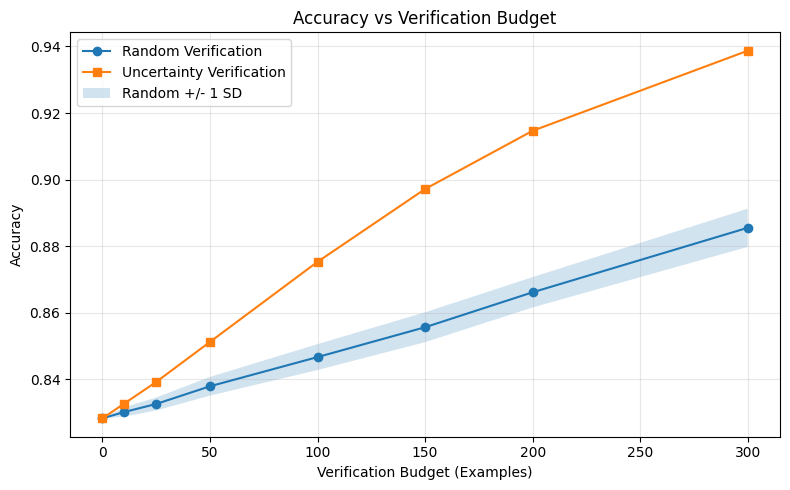

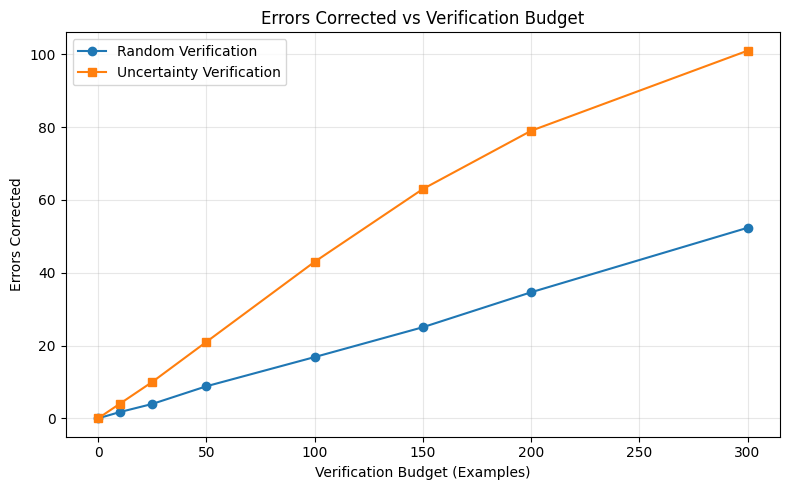


Saved:
verification_statistics.csv
verification_accuracy_curve.png
errors_corrected_curve.png


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Statistical Summary and Verification Curves")

df = experiment_results.copy()
df["Errors_Corrected"] = np.rint(
    (df["Accuracy"] - accuracy_score(y_true, y_pred)) * len(y_true)
).astype(int)

summary_stats = df.groupby(["Budget", "Strategy"]).agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Mean_Macro_F1=("Macro_F1", "mean"),
    Mean_Errors_Corrected=("Errors_Corrected", "mean")
).reset_index()

summary_stats["Std_Accuracy"] = summary_stats["Std_Accuracy"].fillna(0)

print("\nStatistical Summary:")
print(summary_stats.round(4).to_string(index=False))

unc = summary_stats[summary_stats["Strategy"] == "Uncertainty"]
rnd = summary_stats[summary_stats["Strategy"] == "Random"]

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(rnd["Budget"], rnd["Mean_Accuracy"],
        marker="o", label="Random Verification")

ax.plot(unc["Budget"], unc["Mean_Accuracy"],
        marker="s", label="Uncertainty Verification")

ax.fill_between(
    rnd["Budget"].to_numpy(),
    (rnd["Mean_Accuracy"] - rnd["Std_Accuracy"]).to_numpy(),
    (rnd["Mean_Accuracy"] + rnd["Std_Accuracy"]).to_numpy(),
    alpha=0.2,
    label="Random +/- 1 SD"
)

ax.set_xlabel("Verification Budget (Examples)")
ax.set_ylabel("Accuracy")
ax.set_title("Accuracy vs Verification Budget")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("verification_accuracy_curve.png", dpi=300)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(rnd["Budget"], rnd["Mean_Errors_Corrected"],
        marker="o", label="Random Verification")

ax.plot(unc["Budget"], unc["Mean_Errors_Corrected"],
        marker="s", label="Uncertainty Verification")

ax.set_xlabel("Verification Budget (Examples)")
ax.set_ylabel("Errors Corrected")
ax.set_title("Errors Corrected vs Verification Budget")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("errors_corrected_curve.png", dpi=300)
plt.show()

summary_stats.to_csv("verification_statistics.csv", index=False)

print("\nSaved:")
print("verification_statistics.csv")
print("verification_accuracy_curve.png")
print("errors_corrected_curve.png")

10. Held-Out Test Evaluation

In [14]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

print("Held-Out Test Evaluation")

budget = 100
repeats = 100
rng = np.random.default_rng(42)

test_clean = test[
    ~test["string"].isin(set(train["string"]))
].copy()

print("Original test size:", len(test))
print("Evaluation test size:", len(test_clean))

y_test = test_clean["label"].to_numpy()
test_pred = svm_model.predict(test_clean["string"])

test_scores = svm_model.decision_function(test_clean["string"])
sorted_scores = np.sort(test_scores, axis=1)
test_margins = sorted_scores[:, -1] - sorted_scores[:, -2]

baseline_accuracy = accuracy_score(y_test, test_pred)
baseline_f1 = f1_score(y_test, test_pred, average="macro")

order = np.argsort(test_margins, kind="stable")
selected = order[:budget]

unc_pred = test_pred.copy()
unc_pred[selected] = y_test[selected]

rows = [{
    "Strategy": "Baseline",
    "Run": 0,
    "Accuracy": baseline_accuracy,
    "Macro_F1": baseline_f1
}, {
    "Strategy": "Uncertainty",
    "Run": 0,
    "Accuracy": accuracy_score(y_test, unc_pred),
    "Macro_F1": f1_score(y_test, unc_pred, average="macro")
}]

for run in range(repeats):
    selected = rng.choice(len(y_test), size=budget, replace=False)
    corrected = test_pred.copy()
    corrected[selected] = y_test[selected]

    rows.append({
        "Strategy": "Random",
        "Run": run + 1,
        "Accuracy": accuracy_score(y_test, corrected),
        "Macro_F1": f1_score(y_test, corrected, average="macro")
    })

test_results = pd.DataFrame(rows)

summary = test_results.groupby("Strategy").agg(
    Mean_Accuracy=("Accuracy", "mean"),
    Std_Accuracy=("Accuracy", "std"),
    Mean_Macro_F1=("Macro_F1", "mean")
).fillna(0)

print("\nHeld-Out Test Results:")
print(summary.round(6).to_string())

print("\nBaseline Errors:", np.sum(y_test != test_pred))
print("Uncertainty Errors Corrected:",
      np.sum(test_pred[:0] != y_test[:0]) +
      np.sum(test_pred[order[:budget]] != y_test[order[:budget]]))

test_results.to_csv("heldout_test_results.csv", index=False)
summary.to_csv("heldout_test_summary.csv")

print("\nSaved:")
print("heldout_test_results.csv")
print("heldout_test_summary.csv")

Held-Out Test Evaluation
Original test size: 1859
Evaluation test size: 1859

Held-Out Test Results:
             Mean_Accuracy  Std_Accuracy  Mean_Macro_F1
Strategy                                               
Baseline          0.823023      0.000000       0.803991
Random            0.832356      0.002158       0.814303
Uncertainty       0.850995      0.000000       0.834894

Baseline Errors: 329
Uncertainty Errors Corrected: 52

Saved:
heldout_test_results.csv
heldout_test_summary.csv


11. Paper-Disjoint Robustness Analysis

In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

print("Paper-Disjoint Robustness Analysis")

train_papers = set(train["citingPaperId"].dropna())

paper_disjoint = test[
    ~test["citingPaperId"].isin(train_papers)
].copy()

y_true_11 = paper_disjoint["label"].to_numpy()
y_pred_11 = svm_model.predict(paper_disjoint["string"])

scores_11 = svm_model.decision_function(paper_disjoint["string"])
sorted_11 = np.sort(scores_11, axis=1)
margins_11 = sorted_11[:, -1] - sorted_11[:, -2]

budget_11 = round(len(paper_disjoint) * 100 / 1859)
order_11 = np.argsort(margins_11, kind="stable")

baseline_acc = accuracy_score(y_true_11, y_pred_11)
baseline_f1 = f1_score(y_true_11, y_pred_11, average="macro")

unc_pred_11 = y_pred_11.copy()
unc_pred_11[order_11[:budget_11]] = y_true_11[order_11[:budget_11]]

rng = np.random.default_rng(42)
random_rows = []

for run in range(100):
    selected = rng.choice(
        len(y_true_11), size=budget_11, replace=False
    )

    corrected = y_pred_11.copy()
    corrected[selected] = y_true_11[selected]

    random_rows.append({
        "Run": run + 1,
        "Accuracy": accuracy_score(y_true_11, corrected),
        "Macro_F1": f1_score(y_true_11, corrected, average="macro")
    })

random_df_11 = pd.DataFrame(random_rows)

summary_11 = pd.DataFrame([
    {
        "Strategy": "Baseline",
        "Accuracy": baseline_acc,
        "Macro_F1": baseline_f1
    },
    {
        "Strategy": "Random",
        "Accuracy": random_df_11["Accuracy"].mean(),
        "Macro_F1": random_df_11["Macro_F1"].mean()
    },
    {
        "Strategy": "Uncertainty",
        "Accuracy": accuracy_score(y_true_11, unc_pred_11),
        "Macro_F1": f1_score(y_true_11, unc_pred_11, average="macro")
    }
])

print("Original test examples:", len(test))
print("Paper-disjoint examples:", len(paper_disjoint))
print("Excluded examples:", len(test) - len(paper_disjoint))
print("Review budget:", budget_11)

print("\nPaper-Disjoint Results:")
print(summary_11.round(6).to_string(index=False))

print("\nBaseline Errors:", np.sum(y_true_11 != y_pred_11))
print(
    "Uncertainty Errors Corrected:",
    np.sum(
        y_true_11[order_11[:budget_11]] !=
        y_pred_11[order_11[:budget_11]]
    )
)

summary_11.to_csv("paper_disjoint_results.csv", index=False)
random_df_11.to_csv("paper_disjoint_random_runs.csv", index=False)

print("\nSaved:")
print("paper_disjoint_results.csv")
print("paper_disjoint_random_runs.csv")

Paper-Disjoint Robustness Analysis
Original test examples: 1859
Paper-disjoint examples: 1624
Excluded examples: 235
Review budget: 87

Paper-Disjoint Results:
   Strategy  Accuracy  Macro_F1
   Baseline  0.816502  0.805048
     Random  0.826619  0.815844
Uncertainty  0.842980  0.833072

Baseline Errors: 298
Uncertainty Errors Corrected: 43

Saved:
paper_disjoint_results.csv
paper_disjoint_random_runs.csv


12. Export the experimental evidence package

In [16]:
import os
import json
import sys
import shutil
import zipfile
import platform
import pandas as pd
import sklearn
import numpy as np

print("Experimental Evidence Export")

folder = "ATR_Experimental_Evidence"
os.makedirs(folder, exist_ok=True)

files_to_save = [
    "baseline_comparison.csv",
    "baseline_clean_results.csv",
    "svm_confusion_matrix.png",
    "svm_errors.csv",
    "train_validation_overlap.csv",
    "svm_uncertainty_scores.csv",
    "verification_all_runs.csv",
    "verification_summary.csv",
    "verification_statistics.csv",
    "verification_accuracy_curve.png",
    "errors_corrected_curve.png",
    "heldout_test_results.csv",
    "heldout_test_summary.csv",
    "paper_disjoint_results.csv",
    "paper_disjoint_random_runs.csv"
]

missing = []

for filename in files_to_save:
    if os.path.isfile(filename):
        shutil.copy2(filename, os.path.join(folder, filename))
    else:
        missing.append(filename)

environment = {
    "python": sys.version,
    "platform": platform.platform(),
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "random_seed": 42,
    "random_repetitions": 100,
    "primary_test_budget": 100,
    "correction_type": "Perfect oracle simulation",
    "train_size": len(train),
    "validation_size": len(val),
    "clean_validation_size": len(clean_val),
    "test_size": len(test),
    "paper_disjoint_size": len(paper_disjoint)
}

with open(os.path.join(folder, "environment.json"), "w") as f:
    json.dump(environment, f, indent=2)

experiment_summary = {
    "model": "TF-IDF + Linear SVM",
    "primary_metric": "accuracy",
    "secondary_metric": "macro-F1",
    "test_baseline_accuracy": float(baseline_accuracy),
    "test_baseline_macro_f1": float(baseline_f1),
    "test_uncertainty_accuracy": float(
        summary.loc["Uncertainty", "Mean_Accuracy"]
    ),
    "test_random_mean_accuracy": float(
        summary.loc["Random", "Mean_Accuracy"]
    ),
    "test_uncertainty_errors_corrected": int(
        np.sum(test_pred[order[:100]] != y_test[order[:100]])
    ),
    "paper_disjoint_accuracy": float(
        summary_11.loc[
            summary_11["Strategy"] == "Uncertainty", "Accuracy"
        ].iloc[0]
    )
}

with open(os.path.join(folder, "experiment_summary.json"), "w") as f:
    json.dump(experiment_summary, f, indent=2)

zip_name = "ATR_Experimental_Evidence.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in os.listdir(folder):
        z.write(
            os.path.join(folder, filename),
            arcname=filename
        )

print("Evidence package:", zip_name)
print("Files included:", len(os.listdir(folder)))
print("Missing files:", missing)

from google.colab import files
files.download(zip_name)

Experimental Evidence Export
Evidence package: ATR_Experimental_Evidence.zip
Files included: 17
Missing files: []


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>